# H2: Comprehensive Project — Implementation & Review

**FIT1061 Introduction to Artificial Intelligence — HD Task 2**

H1 defined the problem and justified the approach. H2 is where you build, evaluate, and review. Implement the system you scoped in H1, run honest experiments, and write up what worked, what didn't, and what you'd do differently. H3 then defends the full arc in the W14 interview.

> **Prerequisite:** H1 (Complete). Re-read your H1 problem definition before starting.

> **No milestone discussion at H2.** H1 had the discussion; H3 (W14 interview) defends this work.

> H2 should adapt course techniques to a meaningful problem with more depth than a straightforward earlier task. Optional D4 Coin Clash enrichment is available in OnTrack but is not an assessment benchmark or prerequisite.

---

## Recap from H1: what you committed to

*Copied from my H1 plan. I will review and update this recap if my implementation changes.*

**Problem (from H1):**

In office buildings, electricity can be wasted when lights or air conditioning are left running in empty rooms. This gave me the idea for RoomSense, a small neural network that uses temperature, humidity, light and CO₂ readings to predict whether a room is occupied. The goal is to help facilities staff identify rooms worth checking for unnecessary energy use. RoomSense will only make predictions, not control electricity.

**Technique(s) (from H1):**

I will build a small feedforward neural network with Python and NumPy. It will take four sensor readings, use one hidden layer with six neurons and produce an occupancy score between 0 and 1. Gradient descent and backpropagation will adjust its weights during training. This connects to P8 weighted-sum classification, P9 gradient descent and D3 perceptrons.

**Data (from H1):**

I will use the UCI Occupancy Detection dataset, which contains 20,560 labelled office-room observations. It includes temperature, humidity, light, CO₂ and humidity ratio. The occupancy label is 0 (empty) or 1 (occupied). I will use the first four sensor readings as inputs and the provided training and test files for evaluation.

Dataset: https://archive.ics.uci.edu/dataset/357/occupancy-detection

**What makes this HD-level (from H1):**

My plan is to build and understand a small neural network from scratch, compare it with my P8 weighted-sum classifier, and investigate how learning rates and unreliable sensor readings affect its results. The comparison could also show that the simpler model is enough for this dataset.

**Pivot since H1 (if any):**

No change currently planned. I will record any necessary changes and the reasons here.


In [43]:
# --- SETUP ---

import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Use a fixed seed to make results reproducible
SEED = 42
np.random.seed(SEED)

# Project folders
DATA_DIR = Path("data/raw")
FIGURES_DIR = Path("figures")

DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Check the environment
print("RoomSense Setup")
print("Python version:", sys.version.split()[0])
print("NumPy version:", np.__version__)
print("Current folder:", Path.cwd())
print("Setup OK!")

RoomSense Setup
Python version: 3.12.15
NumPy version: 2.5.4
Current folder: d:\Projects\RoomSense
Setup OK!


### Data

In [44]:
# --- DATA ---

import csv

# The four sensor measurements we want to use
features = ["Temperature", "Humidity", "Light", "CO2"]

def load_data(filename):
    file_path = DATA_DIR / filename

    with open(file_path, "r", newline="") as file:
        reader = csv.reader(file)
        header = next(reader)
        rows = list(reader)

    # UCI files include a row ID column
    if len(rows[0]) == len(header) + 1:
        header = ["row_id"] + header

    # Find the columns we need
    feature_indices = [header.index(name) for name in features]
    label_index = header.index("Occupancy")

    # Convert data into NumPy arrays
    X = np.array([
        [float(row[i]) for i in feature_indices]
        for row in rows
    ])

    y = np.array([
        int(row[label_index]) for row in rows
    ])

    return X, y


# Load the original training and testing files
X_train_full, y_train_full = load_data("datatraining.txt")
X_test1, y_test1 = load_data("datatest.txt")
X_test2, y_test2 = load_data("datatest2.txt")

print("Training observations:", len(X_train_full))
print("Test 1 observations:", len(X_test1))
print("Test 2 observations:", len(X_test2))
print("Features:", features)
print("First sensor reading:", X_train_full[0])
print("First occupancy label:", y_train_full[0])

Training observations: 8143
Test 1 observations: 2665
Test 2 observations: 9752
Features: ['Temperature', 'Humidity', 'Light', 'CO2']
First sensor reading: [ 23.18   27.272 426.    721.25 ]
First occupancy label: 1


In [45]:
# Check how many rooms were occupied or empty

labels, counts = np.unique(y_train_full, return_counts=True)

for label, count in zip(labels, counts):
    percentage = count / len(y_train_full) * 100

    print(f"Class {label}: {count} observations ({percentage:.2f}%)")

Class 0: 6414 observations (78.77%)
Class 1: 1729 observations (21.23%)


### Data Exploration

I loaded the UCI Occupancy Detection dataset using Python and NumPy. I selected four sensor features: temperature, humidity, light and CO2. The occupancy label shows whether the room was empty (0) or occupied (1).

I also checked the number of observations in each class to understand whether the dataset is balanced. This is important because a classifier might achieve high accuracy by predicting the more common class too often.


In [46]:

# --- TRAINING AND VALIDATION SPLIT ---

# Use 80% for training and 20% for validation
split_index = int(len(X_train_full) * 0.8)

# Keep the observations in time order
X_train = X_train_full[:split_index]
y_train = y_train_full[:split_index]

X_val = X_train_full[split_index:]
y_val = y_train_full[split_index:]

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

# Check class distribution
for name, labels in [("Train", y_train), ("Validation", y_val)]:
    counts = np.bincount(labels, minlength=2)
    print(f"{name}: Empty={counts[0]}, Occupied={counts[1]}")

Training shape: (6514, 4)
Validation shape: (1629, 4)
Train: Empty=5373, Occupied=1141
Validation: Empty=1041, Occupied=588


In [47]:

# --- FEATURE STANDARDISATION ---

# Calculate statistics using training data ONLY
train_mean = X_train.mean(axis=0)
train_std = X_train.std(axis=0)

# Avoid division by zero
train_std = np.where(train_std == 0, 1, train_std)

# Standardise training and validation inputs
X_train_norm = (X_train - train_mean) / train_std
X_val_norm = (X_val - train_mean) / train_std

print("Original first reading:", X_train[0])
print("Standardised first reading:", X_train_norm[0])

print("Training means:", X_train_norm.mean(axis=0))
print("Training standard deviations:", X_train_norm.std(axis=0))

Original first reading: [ 23.18   27.272 426.    721.25 ]
Standardised first reading: [2.40216404 0.8097268  1.68936091 1.01372337]
Training means: [ 4.00451684e-13 -1.55943487e-13 -2.70148588e-15  3.72570667e-15]
Training standard deviations: [1. 1. 1. 1.]


### Data Preprocessing

I divided the original training dataset into 80% training data and 20% validation data while keeping the observations in time order. This allows me to train the neural network and check its performance on data that was not used to update its weights.

I also standardised the four sensor readings because they have different numerical scales. I calculated the mean and standard deviation using only the training data to avoid data leakage.

The two official test datasets will be kept separate until the final evaluation.


### Implementation

In [48]:
# --- FORWARD PROPAGATION PRACTICE ---

# Activation function
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

# Reproducible random starting weights
rng = np.random.default_rng(42)

# Four inputs -> six hidden neurons -> one output
demo_W1 = rng.normal(0, 0.1, size=(4, 6))
demo_b1 = np.zeros((1, 6))

demo_W2 = rng.normal(0, 0.1, size=(6, 1))
demo_b2 = np.zeros((1, 1))

# Use five examples from our prepared training data
X_demo = X_train_norm[:5]

# Input -> hidden layer
hidden_values = sigmoid(X_demo @ demo_W1 + demo_b1)

# Hidden layer -> output
predictions = sigmoid(hidden_values @ demo_W2 + demo_b2)

print("Input shape:", X_demo.shape)
print("Hidden shape:", hidden_values.shape)
print("Output shape:", predictions.shape)

print("\nPrediction scores:")
print(predictions.flatten())

Input shape: (5, 4)
Hidden shape: (5, 6)
Output shape: (5, 1)

Prediction scores:
[0.51070071 0.5107047  0.51071237 0.51071438 0.51072826]


In [49]:
# --- PRACTICE: CALCULATING PREDICTION LOSS ---

# Use the same 5 training examples from our forward pass
y_demo = y_train[:5].reshape(-1, 1)

# Use the prediction scores from our previous example
p_demo = predictions

# Keep logarithms numerically safe
epsilon = 1e-10
p_safe = np.clip(p_demo, epsilon, 1 - epsilon)

# Binary cross-entropy loss
loss = -np.mean(
    y_demo * np.log(p_safe)
    + (1 - y_demo) * np.log(1 - p_safe)
)

print("Actual labels:", y_demo.flatten())
print("Prediction scores:", p_demo.flatten())
print("Binary cross-entropy loss:", round(loss, 6))

Actual labels: [1 1 1 1 1]
Prediction scores: [0.51070071 0.5107047  0.51071237 0.51071438 0.51072826]
Binary cross-entropy loss: 0.671949


### Understanding Neural Network Training

RoomSense first uses forward propagation to make predictions from the sensor readings. Since the weights start randomly, the initial predictions are not expected to be accurate.

Binary cross-entropy measures the difference between the predictions and actual occupancy labels.

Backpropagation calculates gradients showing how each weight affects the loss. Gradient descent then uses these gradients to update the weights and reduce errors.

This connects to P9 because both methods use gradients to move towards a lower loss value. The main difference is that the neural network has many weights and biases to update.

In [50]:
# --- PRACTICE: ONE GRADIENT DESCENT UPDATE ---

x = 1.0
y = 1.0

weight = 0.2
bias = 0.0
learning_rate = 0.1

# Prediction before training
prediction_before = sigmoid(weight * x + bias)

# Calculate gradient
gradient = (prediction_before - y) * x

# Update the weight
new_weight = weight - learning_rate * gradient

# Prediction after updating
prediction_after = sigmoid(new_weight * x + bias)

print("Original weight:", round(weight, 4))
print("Updated weight:", round(new_weight, 4))
print("Prediction before:", round(prediction_before, 4))
print("Prediction after:", round(prediction_after, 4))

Original weight: 0.2
Updated weight: 0.245
Prediction before: 0.5498
Prediction after: 0.5609


In [51]:
# --- OUTPUT LAYER GRADIENTS ---

m = len(X_demo)

# Error at the output layer
dZ2 = predictions - y_demo

# Gradients for output weights and bias
dW2 = hidden_values.T @ dZ2 / m
db2 = np.mean(dZ2, axis=0, keepdims=True)

print("Output weight gradient shape:", dW2.shape)
print("Output bias gradient shape:", db2.shape)

Output weight gradient shape: (6, 1)
Output bias gradient shape: (1, 1)


In [52]:
# --- HIDDEN LAYER BACKPROPAGATION ---

# Step 1: Pass the output error backwards
# Sigmoid derivative = H * (1 - H)
dZ1 = (dZ2 @ demo_W2.T) * hidden_values * (1 - hidden_values)

# Step 2: Calculate hidden weight gradients
dW1 = (X_demo.T @ dZ1) / m

# Step 3: Calculate hidden bias gradients
db1 = np.mean(dZ1, axis=0, keepdims=True)

# Test the gradient shapes
assert dW1.shape == (4, 6)
assert db1.shape == (1, 6)

print("Hidden layer gradient shapes are correct!")
print("dZ1 shape:", dZ1.shape)
print("dW1 shape:", dW1.shape)
print("db1 shape:", db1.shape)

Hidden layer gradient shapes are correct!
dZ1 shape: (5, 6)
dW1 shape: (4, 6)
db1 shape: (1, 6)


### Backpropagation and Gradient Descent Notes

- Forward propagation is when the neural network calculates its prediction.
- Loss measures how wrong the prediction is.
- Backpropagation calculates gradients for the weights and biases.
- Gradient descent updates those values to reduce the loss.
- The learning rate controls how large each update is.
- A learning rate that is too large can make training unstable.
- A learning rate that is too small can make training very slow.

This connects to P9 Gradient Descent because both methods use derivatives to reduce errors.

In [53]:
# --- TEST: ONE COMPLETE GRADIENT DESCENT UPDATE ---

learning_rate = 0.1
m = len(X_demo)

# Calculate the predictions using the current weights
H = sigmoid(X_demo @ demo_W1 + demo_b1)
P = sigmoid(H @ demo_W2 + demo_b2)

# Binary cross-entropy
def binary_cross_entropy(y_true, y_pred):
    p = np.clip(y_pred, 1e-10, 1 - 1e-10)

    return -np.mean(
        y_true * np.log(p)
        + (1 - y_true) * np.log(1 - p)
    )

loss_before = binary_cross_entropy(y_demo, P)

# Calculate output layer gradients
dZ2 = P - y_demo
dW2 = H.T @ dZ2 / m
db2 = np.mean(dZ2, axis=0, keepdims=True)

# Calculate hidden layer gradients
dZ1 = (dZ2 @ demo_W2.T) * H * (1 - H)
dW1 = X_demo.T @ dZ1 / m
db1 = np.mean(dZ1, axis=0, keepdims=True)

# Update all weights and biases
W1_new = demo_W1 - learning_rate * dW1
b1_new = demo_b1 - learning_rate * db1

W2_new = demo_W2 - learning_rate * dW2
b2_new = demo_b2 - learning_rate * db2

# Forward pass after updating
H_new = sigmoid(X_demo @ W1_new + b1_new)
P_new = sigmoid(H_new @ W2_new + b2_new)

loss_after = binary_cross_entropy(y_demo, P_new)

print("Loss before:", round(loss_before, 6))
print("Loss after: ", round(loss_after, 6))
print("Loss decreased:", loss_after < loss_before)

Loss before: 0.671949
Loss after:  0.615325
Loss decreased: True


In [54]:
# --- ROOMSENSE TRAINING LOOP ---

def train_roomsense(X, y, X_val, y_val,
                   learning_rate=0.1, epochs=300, seed=42):

    rng = np.random.default_rng(seed)

    # Initialise weights and biases
    W1 = rng.normal(0, 0.1, size=(4, 6))
    b1 = np.zeros((1, 6))

    W2 = rng.normal(0, 0.1, size=(6, 1))
    b2 = np.zeros((1, 1))

    y = y.reshape(-1, 1)
    y_val = y_val.reshape(-1, 1)

    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        # Step 1: Forward propagation
        H = sigmoid(X @ W1 + b1)
        P = sigmoid(H @ W2 + b2)

        # Step 2: Backpropagation
        m = len(X)

        dZ2 = P - y
        dW2 = H.T @ dZ2 / m
        db2 = np.mean(dZ2, axis=0, keepdims=True)

        dZ1 = (dZ2 @ W2.T) * H * (1 - H)
        dW1 = X.T @ dZ1 / m
        db1 = np.mean(dZ1, axis=0, keepdims=True)

        # Step 3: Gradient descent
        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1

        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

        # Step 4: Calculate updated training loss
        H_train = sigmoid(X @ W1 + b1)
        P_train = sigmoid(H_train @ W2 + b2)

        train_loss = binary_cross_entropy(y, P_train)

        # Step 5: Calculate validation loss
        H_val = sigmoid(X_val @ W1 + b1)
        P_val = sigmoid(H_val @ W2 + b2)

        val_loss = binary_cross_entropy(y_val, P_val)

        # Step 6: Store loss values
        train_losses.append(train_loss)
        val_losses.append(val_loss)

    return W1, b1, W2, b2, train_losses, val_losses


# --- TRAIN ROOMSENSE ---

W1, b1, W2, b2, train_losses, val_losses = train_roomsense(
    X_train_norm,
    y_train,
    X_val_norm,
    y_val,
    learning_rate=0.1,
    epochs=300
)

print("Training completed!")
print("Initial training loss:", round(train_losses[0], 4))
print("Final training loss:", round(train_losses[-1], 4))
print("Final validation loss:", round(val_losses[-1], 4))

Training completed!
Initial training loss: 0.6825
Final training loss: 0.2077
Final validation loss: 0.3544


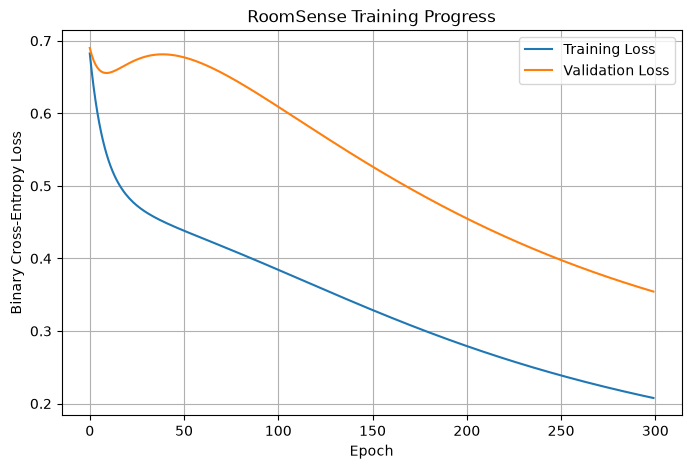

In [55]:
# --- VISUALISE TRAINING PROGRESS ---

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("RoomSense Training Progress")

plt.legend()
plt.grid(True)
plt.show()

### Comparison

In [60]:
# --- WEIGHTED-SUM BASELINE ---

def train_baseline(X, y, learning_rate=0.1, epochs=300):

    # A weighted-sum model has one weight per feature
    weights = np.zeros((X.shape[1], 1))
    bias = 0.0

    y = y.reshape(-1, 1)
    losses = []

    for epoch in range(epochs):

        # Step 1: Calculate weighted sum
        z = X @ weights + bias

        # Step 2: Convert to prediction scores
        predictions = sigmoid(z)

        # Step 3: Calculate the error
        error = predictions - y

        # Step 4: Calculate gradients
        m = len(X)
        dW = X.T @ error / m
        db = np.mean(error)

        # Step 5: Update weights and bias
        weights -= learning_rate * dW
        bias -= learning_rate * db

        # Step 6: Record updated training loss
        updated_predictions = sigmoid(X @ weights + bias)

        loss = binary_cross_entropy(y, updated_predictions)
        losses.append(loss)

    return weights, bias, losses


# Train the baseline on the same training data
baseline_W, baseline_b, baseline_losses = train_baseline(
    X_train_norm,
    y_train,
    learning_rate=0.1,
    epochs=300
)

print("Baseline training completed!")
print("Initial loss:", round(baseline_losses[0], 4))
print("Final loss:", round(baseline_losses[-1], 4))

Baseline training completed!
Initial loss: 0.658
Final loss: 0.0962


### Evaluation

In [61]:
# --- MODEL COMPARISON ---

def evaluate_model(y_true, y_pred):

    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()

    # Confusion matrix counts
    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))

    accuracy = (TP + TN) / len(y_true)

    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0

    # F1 score for occupied and empty classes
    f1_occupied = (
        2 * TP / (2 * TP + FP + FN)
        if 2 * TP + FP + FN > 0 else 0
    )

    f1_empty = (
        2 * TN / (2 * TN + FP + FN)
        if 2 * TN + FP + FN > 0 else 0
    )

    macro_f1 = (f1_occupied + f1_empty) / 2

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Occupied Recall": recall,
        "Macro-F1": macro_f1,
        "False Negatives": int(FN)
    }


# Baseline predictions
baseline_scores = sigmoid(
    X_val_norm @ baseline_W + baseline_b
)

baseline_predictions = (
    baseline_scores >= 0.5
).astype(int)


# Neural network predictions
hidden = sigmoid(X_val_norm @ W1 + b1)

nn_scores = sigmoid(hidden @ W2 + b2)

nn_predictions = (
    nn_scores >= 0.5
).astype(int)


# Evaluate both models
baseline_results = evaluate_model(
    y_val, baseline_predictions
)

nn_results = evaluate_model(
    y_val, nn_predictions
)


# Display comparison
print("VALIDATION RESULTS")
print("-" * 55)

print(f"{'Metric':20} {'Baseline':>12} {'Neural Net':>12}")

for metric in baseline_results:
    b = baseline_results[metric]
    n = nn_results[metric]

    if metric == "False Negatives":
        print(f"{metric:20} {b:12d} {n:12d}")
    else:
        print(f"{metric:20} {b:12.4f} {n:12.4f}")

VALIDATION RESULTS
-------------------------------------------------------
Metric                   Baseline   Neural Net
Accuracy                   0.8950       0.8711
Precision                  0.8044       0.9749
Occupied Recall            0.9371       0.6599
Macro-F1                   0.8898       0.8473
False Negatives                37          200


### Weighted-Sum Baseline Comparison

I implemented a weighted-sum classifier as a simpler alternative to my neural network. It uses the same four sensor inputs but does not have a hidden layer.

The baseline calculates a weighted sum, applies sigmoid and uses a threshold of 0.5 to classify room occupancy.

I trained both models using the same training split and evaluated them using the same validation split.

I compared accuracy, precision, occupied-room recall, macro-F1 and false negatives. This helps me determine whether the additional complexity of the neural network provides a meaningful improvement.

### Experiment 1

In [56]:
# --- EXPERIMENT 1 ---

# --- YOUR CODE HERE ---

# --- END YOUR CODE ---

### Experiment 2

In [57]:
# --- EXPERIMENT 2 ---

# --- YOUR CODE HERE ---

# --- END YOUR CODE ---

### Visualisation 1

In [58]:
# --- VISUALISATION 1 ---

# --- YOUR CODE HERE ---

# --- END YOUR CODE ---

### Visualisation 2

In [59]:
# --- VISUALISATION 2 ---

# --- YOUR CODE HERE ---

# --- END YOUR CODE ---

---

## H2.2: Project Report (~1500 words)

### 1. Problem Definition and Motivation (~200 words)

What problem did you solve? Why does it matter? Why is AI the right approach? (Build on H1; don't just paste it.)

*(Write here)*

### 2. Technical Approach (~300 words)

What technique(s) did you use? How did you adapt or extend them? What design decisions did you make and why?

*(Write here)*

### 3. Results and Analysis (~400 words)

What worked? What didn't? Reference your visualisations. How does performance change across experiments? Surprising findings?

*(Write here)*

### 4. Limitations and Future Work (~200 words)

Where does your approach fail? What assumptions are violated? What would you do with more time? Be specific.

*(Write here)*

### 5. Ethical Reflection (~200 words)

If deployed, who is affected? What failure modes matter most? Connect to at least one concept from C2 (Classification & Fairness) or C4 (Deployment & Model Cards).

*(Write here)*

### 6. AI Use Statement (~100 words)

How did you use AI tools? What did you accept? What did you reject, and why?

*(Write here)*

---

## Submission Checklist

- [ ] Recap of H1 scope (and any pivot) at the top
- [ ] Working notebook with data, implementation, 2+ experiments, 2+ visualisations
- [ ] Project report (~1500 words) covering all 6 sections
- [ ] Implementation demonstrates HD-level depth beyond earlier task work
- [ ] Ethical reflection connects to C2 or C4
- [ ] AI use statement shows critical evaluation
- [ ] Code is readable, reproducible, documented
- [ ] Uploaded to OnTrack and marked **Ready for Feedback**
- [ ] H3 interview booking confirmed for W14

---

*FIT1061 HD Task H2: Comprehensive Project: Implementation & Review*